# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: CRUZADO, JOHN CLARENCE
- _Student No._: 2024-03034
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Fig1.png](Fig1.png)

**Figure 1. Synthetic data interpolation.**
Figure 1 shows the plots comparing the true sine function $f(x) = \frac{1}{2}\sin{2x}$ against sampled data points reconstructed using linear interpolation and cubic-fitting methods.

![Fig2.png](Fig2.png)

**Figure 2. Real-world data reconstruction.**
Figure 2 shows the Dow Jones time-series reconstruction using sparse sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:**
The different models show distinct behaviors based on how they connect discrete data points. We primarily compared the linear and cubic models in interpolating both synthetic and real-world data.

For a fixed sampling size, linear interpolation (using straight line segments), features angular corners at each sampling point where the resulting line is piecewise continuous. While this avoids overshooting the true data curve, the approximation of smooth trends returns a curve that may not entirely capture data points at smoother transitions, especially if the data is scattered or does not cluster at a short interval. When it comes to modelling real-world data like the Dow Jones, they achieve a good approximation of the shape of the true function, making it a good benchmark for handling such data where it is not smooth and defined by a single well-behaved function.

On the other hand, for cubic-fitting using smooth splines, they achieve the highest accuracy by matching the curvature (preserving the first and second derivatives of the function) to prevent abrupt changes in the slope, which is particularly helpful in smooth or well-behaved functions like the synthetic sine waves. As for handling real-world data where there is significant noise, cubic splines tend to overshoot and create wild oscillations between points, resulting into peaks and valleys that never actually occurred in the market.

**Sampling-level comparison:**
When the sample size is dense (50% or 30%), the dataset generally captures the major trends, including both macro-trends and micro-fluctuations that resemble market volatility. In dense datasets, both linear and cubic models yield nearly identical and highly accurate representations of the true function because the distance between adjacent points is small with minimal rrisk of missing points of inflections.

However, when we move towards smaller sample sizes (10% and 5%), we notice the difference in using linear and cubic models. While they outline the overall shape of the true curve, they tend to bridge adjacent points that are far away from each other, introducing jagged lines (linear) or 
smoothing artifacts (cubic). At the lower end (5%), the model is severely constrained and vulnerable to reconstruction errors. When there are large gaps between sample points, critical peaks and valleys are almost always missed by the model. Linear models particularly underrepresent data variance while cubic models suffer from wide polynomial spans that frequently overshoot/undershoot wildly between distantt points to maintain the continuity based on existing data sets.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, make_interp_spline
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

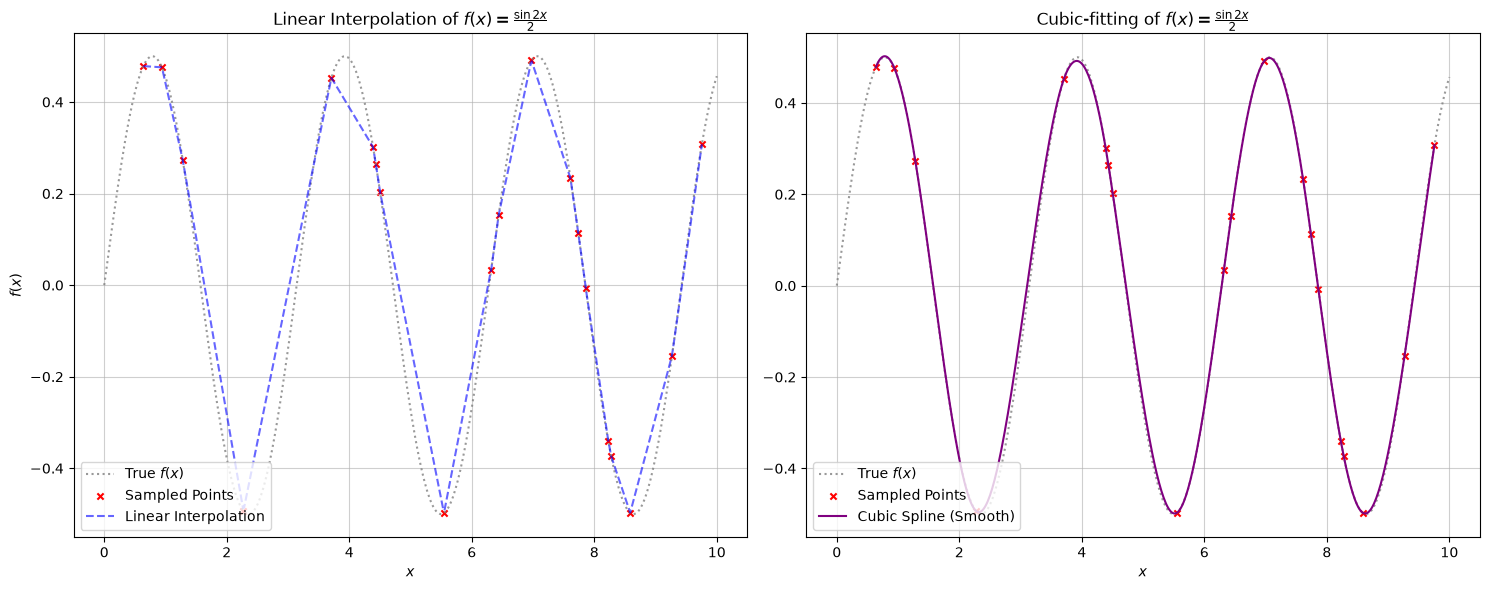

In [2]:
#Problem 1

def truesine(x):
    return np.sin(2*x) / 2

x = np.linspace(0,10,500)
sample_x = np.sort(rng.uniform(0,10,20))
sample_points = truesine(sample_x)

# Creating the X-grid
x_dense = np.linspace(sample_x.min(), sample_x.max(), 500)

linear_model = interp1d(sample_x, sample_points, kind='linear')
cubic_model = make_interp_spline(sample_x, sample_points, k=3)

f_linear = linear_model(x_dense)
f_cubic = cubic_model(x_dense)

plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.plot(x, truesine(x),color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
plt.scatter(sample_x, sample_points, color="red", s=20, marker="x", label=r"Sampled Points")
plt.plot(x_dense, f_linear, label="Linear Interpolation", ls="--", color="blue", alpha=0.6)
plt.xlabel(r"$x$")
plt.ylabel(r"$f(x)$")
plt.title(r"Linear Interpolation of $f(x)=\frac{\sin{2x}}{2}$")
plt.grid(True, alpha=0.6)
plt.legend(loc="lower left")

plt.subplot(1,2,2)
plt.plot(x, truesine(x),color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
plt.scatter(sample_x, sample_points, color="red", s=20, marker="x", label=r"Sampled Points")
plt.plot(x_dense, f_cubic, label="Cubic Spline (Smooth)", linestyle="-", color="purple")
plt.xlabel(r"$x$")
plt.title(r"Cubic-fitting of $f(x)=\frac{\sin{2x}}{2}$")
plt.grid(True, alpha=0.6)
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

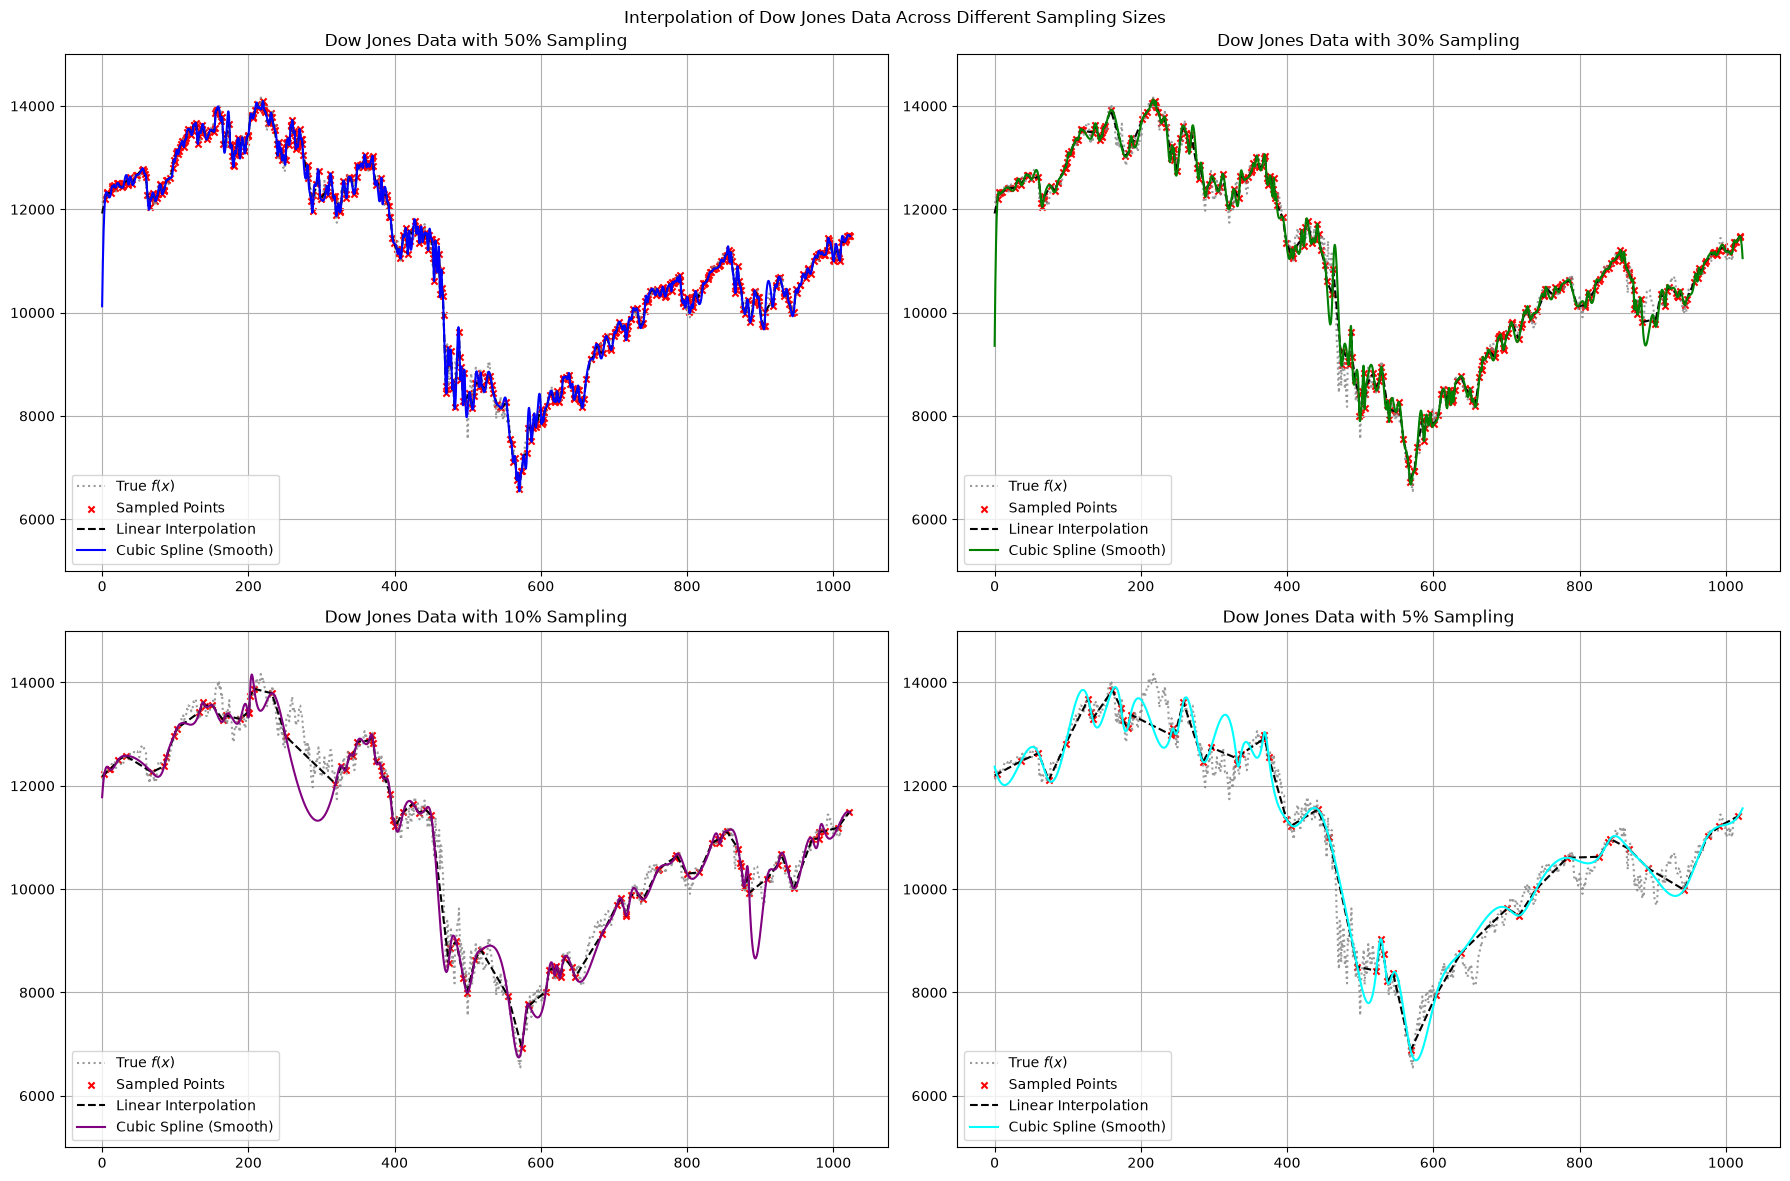

In [4]:
#Problem 2
data_dow = np.loadtxt("dow.txt")

indices_full = np.arange(len(data_dow))
indices_a = rng.choice(indices_full, size=int(len(data_dow) * 0.50), replace=False)
data_a = data_dow[indices_a]

indices_b = rng.choice(indices_full, size=int(len(data_dow) * 0.30), replace=False)
data_b = data_dow[indices_b]

indices_c = rng.choice(indices_full, size=int(len(data_dow) * 0.10), replace=False)
data_c = data_dow[indices_c]

indices_d = rng.choice(indices_full, size=int(len(data_dow) * 0.05), replace=False)
data_d = data_dow[indices_d]

# Creating the X-grid
x_new = np.linspace(indices_full.min(), indices_full.max(), 10000)

samples_info = [
    {"label": "Dow Jones Data with 50% Sampling", "idx": indices_a, "data": data_a, "color": "blue"},
    {"label": "Dow Jones Data with 30% Sampling", "idx": indices_b, "data": data_b, "color": "green"},
    {"label": "Dow Jones Data with 10% Sampling", "idx": indices_c, "data": data_c, "color": "purple"},
    {"label": "Dow Jones Data with 5% Sampling",  "idx": indices_d, "data": data_d, "color": "cyan"}
]

interpolated_results = {}
for sample in samples_info:
    sort_order = np.argsort(sample["idx"])
    x_sorted = sample["idx"][sort_order]
    y_sorted = sample["data"][sort_order]
    
    linear_model = interp1d(x_sorted, y_sorted, kind='linear', fill_value="extrapolate")
    cubic_model = make_interp_spline(x_sorted, y_sorted, k=3)
    
    interpolated_results[sample["label"]] = {
        "y_linear": linear_model(x_new),
        "y_cubic": cubic_model(x_new),
        "x_sorted": x_sorted,
        "y_sorted": y_sorted,
        "color": sample["color"]
    }
plt.figure(figsize=(18,12))

for i, (label, res) in enumerate(interpolated_results.items()):
    plt.subplot(2, 2, i + 1)
    plt.plot(data_dow,color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
    plt.scatter(res["x_sorted"], res["y_sorted"], color="red", s=20, marker="x", label="Sampled Points")
    plt.plot(x_new, res["y_linear"], color="black", ls="--", label="Linear Interpolation")
    plt.plot(x_new, res["y_cubic"], color=res["color"], label="Cubic Spline (Smooth)")
    plt.ylim(5000,15000)
    plt.title(label)
    plt.grid(True)
    plt.legend(loc="lower left")

plt.suptitle("Interpolation of Dow Jones Data Across Different Sampling Sizes")
plt.tight_layout()
plt.show()
    

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

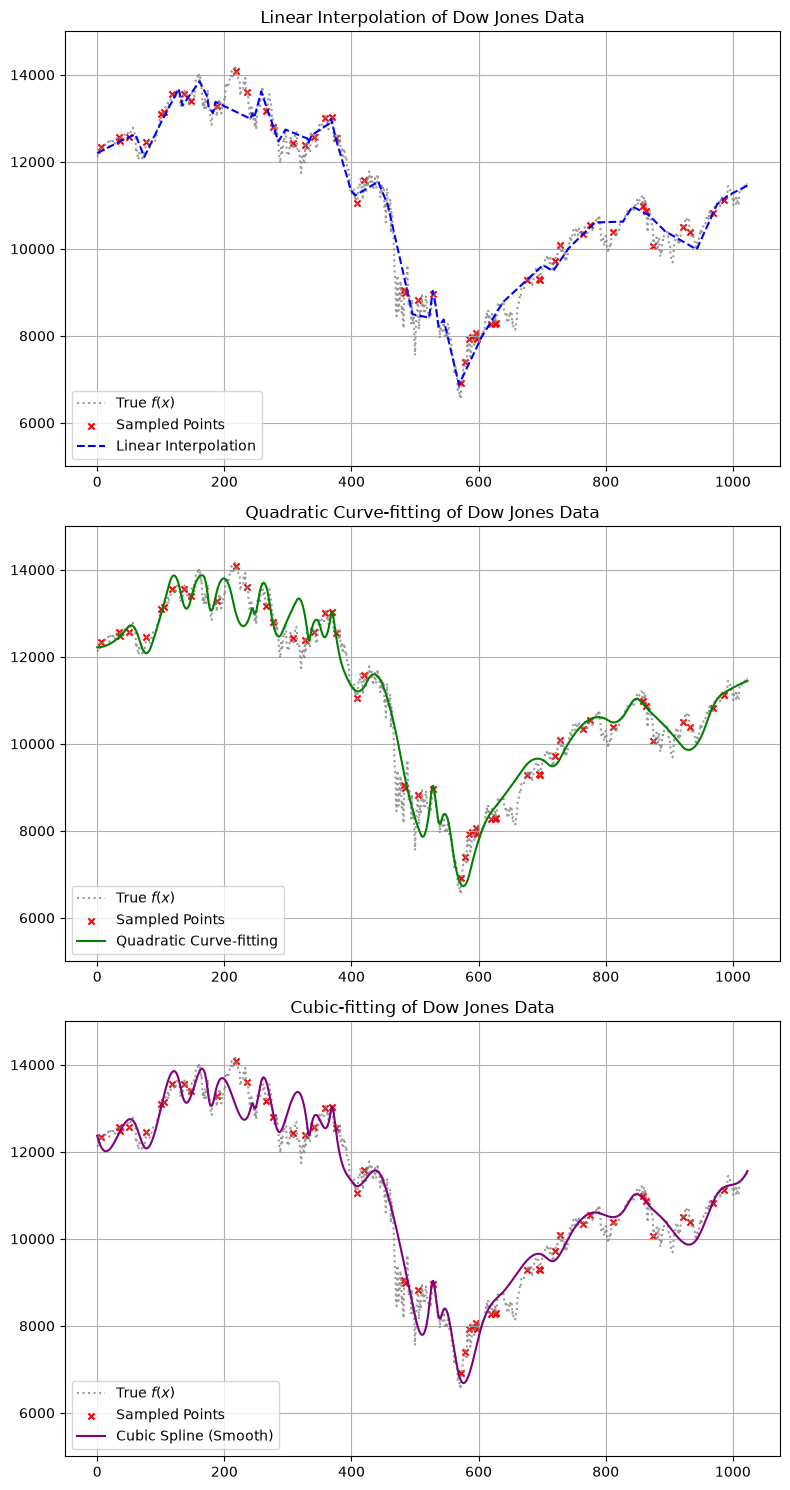

In [5]:
#Problem 3 using 10% Sampling Data

sorted_data = np.argsort(indices_d)

linear_model = interp1d(indices_d[sorted_data], data_d[sorted_data], kind='linear', fill_value="extrapolate")
quad_model = make_interp_spline(indices_d[sorted_data], data_d[sorted_data], k=2)
cubic_model = make_interp_spline(indices_d[sorted_data], data_d[sorted_data], k=3)

f_linear = linear_model(x_new)
f_quad = quad_model(x_new)
f_cubic = cubic_model(x_new)

plt.figure(figsize=(8,15))

plt.subplot(3,1,1)
plt.plot(data_dow,color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
plt.scatter(indices_b[sorted_data],data_b[sorted_data], color="red", s=20, marker="x", label="Sampled Points")
plt.plot(x_new, f_linear, color="blue", ls="--", label="Linear Interpolation")
plt.ylim(5000,15000)
plt.title("Linear Interpolation of Dow Jones Data")
plt.grid(True)
plt.legend(loc="lower left")

plt.subplot(3,1,2)
plt.plot(data_dow,color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
plt.scatter(indices_b[sorted_data],data_b[sorted_data], color="red", s=20, marker="x", label="Sampled Points")
plt.plot(x_new, f_quad, color="green", label="Quadratic Curve-fitting")
plt.ylim(5000,15000)
plt.title("Quadratic Curve-fitting of Dow Jones Data")
plt.grid(True)
plt.legend(loc="lower left")

plt.subplot(3,1,3)
plt.plot(data_dow,color="gray", alpha=0.8, ls=":", label=r"True $f(x)$")
plt.scatter(indices_b[sorted_data],data_b[sorted_data], color="red", s=20, marker="x", label="Sampled Points")
plt.plot(x_new, f_cubic, color="purple", label="Cubic Spline (Smooth)")
plt.ylim(5000,15000)
plt.title("Cubic-fitting of Dow Jones Data")
plt.grid(True)
plt.legend(loc="lower left")
    
plt.tight_layout()
plt.show()

### Problem  code summary


The code compares linear and cubic spline interpolation techniques across synthetic sine waves at a fixed sampling size, then modified the script so that we test four (4) different sampling sizes to compare how well each model interpolates the actual data. Here, we tested different sparsity levels to highlight the resolution and reconstruction of each interpolation model.

---